# 0. Tekst → tokeny → embeddingi → model języka

**Teoria do tego notebooka:** [`00_tekst_tokeny_embeddingi.md`](00_tekst_tokeny_embeddingi.md)

W tym notebooku:

1. wczytamy "Pana Tadeusza" i zamienimy go na liczby (tokenizacja znakowa),
2. zobaczymy na małym przykładzie, jak działa BPE (tokenizacja podsłowowa, używana w prawdziwych LLM-ach),
3. sprawdzimy, że embedding to po prostu wybór wiersza z macierzy,
4. wytrenujemy najprostszy możliwy model języka, **model bigramowy**, który widzi tylko jeden poprzedni znak,
5. podejrzymy, czego nauczyły się embeddingi, i jak temperatura zmienia generowany tekst.

Model bigramowy to punkt odniesienia dla kolejnych rozdziałów: każda architektura z pamięcią
(RNN, LSTM, Transformer, RWKV) powinna być od niego wyraźnie lepsza.

> Wszystko, co nie jest tematem rozdziału (pobieranie danych, pętla treningowa, generowanie), siedzi w
> [`common.py`](common.py). Warto tam zajrzeć: to ~250 linii zwykłego PyTorcha.

In [1]:
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from common import (CharTokenizer, count_params, generate_naive, get_batch, load_pan_tadeusz,
                    prepare_data, save_results, set_seed, train, TrainConfig)

plt.rcParams["figure.dpi"] = 110

## 1. Dane: "Pan Tadeusz"

Tekst jest w domenie publicznej. `load_pan_tadeusz()` pobiera go z Wolnych Lektur (za pierwszym razem),
wycina metryczkę i stopkę licencyjną, a wynik zapisuje w `data/pan_tadeusz.txt`.

In [2]:
text = load_pan_tadeusz()
print(f"{len(text):,} znaków".replace(",", " "))
print(text[:420])

441 267 znaków
Księga pierwsza

Gospodarstwo

Powrót panicza — Spotkanie się pierwsze w pokoiku, drugie u stołu — Ważna Sędziego nauka o grzeczności — Podkomorzego uwagi polityczne nad modami — Początek sporu o Kusego i Sokoła — Żale Wojskiego — Ostatni Woźny Trybunału — Rzut oka na ówczesny stan polityczny Litwy i Europy

Litwo! Ojczyzno moja! ty jesteś jak zdrowie;
Ile cię trzeba cenić, ten tylko się dowie,
Kto cię stracił. Dziś 


## 2. Tokenizacja znakowa

Najprostszy tokenizer: każdy unikalny znak dostaje numer. Słownik to po prostu posortowany zbiór znaków.

In [3]:
tok = CharTokenizer(text)
print("rozmiar słownika V =", tok.vocab_size)
print(repr("".join(tok.chars)))

ids = tok.encode("Litwo! Ojczyzno moja!")
print(ids)
print(tok.decode(ids))

rozmiar słownika V = 87
'\n !()*,-./128:;?ABCDEFGHIJKLMNOPRSTUVWZabcdefghijklmnopqrstuvwxyz«»ÓàæéóąĆćęŁłńŚśŹźŻż—…'
[27, 47, 58, 61, 53, 2, 1, 30, 48, 41, 64, 63, 64, 52, 53, 1, 51, 53, 48, 39, 2]
Litwo! Ojczyzno moja!


## 3. Mini-BPE: skąd się biorą tokeny w prawdziwych modelach

BPE (*Byte Pair Encoding*) zaczyna od znaków i w kółko skleja **najczęstszą parę sąsiednich symboli** w nowy symbol.
Tak jak w GPT-2 (i w tokenizerze modeli RWKV-4 Pile), najpierw tniemy tekst na "słowa" ze spacją na początku,
żeby nie sklejać symboli ponad granicami słów. Liczymy częstości słów raz, potem operujemy na słowniku
`słowo (jako krotka symboli) -> liczba wystąpień`.

In [4]:
words = Counter(re.findall(r" ?\w+| ?[^\w\s]+|\s+", text))
vocab = {tuple(w): c for w, c in words.items()}
print(f"{len(words)} różnych 'słów'; najczęstsze: {words.most_common(8)}")


def most_frequent_pair(vocab):
    pairs = Counter()
    for symbols, count in vocab.items():
        for a, b in zip(symbols, symbols[1:]):
            pairs[a, b] += count
    return pairs.most_common(1)[0]


def merge_pair(vocab, pair):
    a, b = pair
    merged = {}
    for symbols, count in vocab.items():
        out, i = [], 0
        while i < len(symbols):
            if i + 1 < len(symbols) and symbols[i] == a and symbols[i + 1] == b:
                out.append(a + b)
                i += 2
            else:
                out.append(symbols[i])
                i += 1
        merged[tuple(out)] = count
    return merged


merges = []
for _ in range(150):
    pair, count = most_frequent_pair(vocab)
    vocab = merge_pair(vocab, pair)
    merges.append(pair)

print("pierwsze 20 sklejeń:", [a + b for a, b in merges[:20]])
print("sklejenia 130-150:  ", [a + b for a, b in merges[130:150]])

21507 różnych 'słów'; najczęstsze: [('\n', 9135), (',', 9061), ('.', 2120), (' się', 1497), (' w', 1492), (';', 1432), (' i', 1406), (' z', 1232)]


pierwsze 20 sklejeń: ['ie', ' s', ' w', ' p', ' z', 'rz', ' n', 'cz', 'ch', 'sz', ' d', 'ał', ' k', ' t', ' m', 'ra', 'dz', 'ię', ' o', 'ro']
sklejenia 130-150:   ['cy', 'at', 'je', 'ski', ' go', 'usz', 'to', 'uż', ' mo', 'ca', ' pan', 'tó', ' roz', ' tak', 'mo', 'Nie', 'zy', 'ać', 'gi', 'sze']


In [5]:
def bpe_encode(s, merges):
    tokens = []
    for word in re.findall(r" ?\w+| ?[^\w\s]+|\s+", s):
        symbols = list(word)
        for a, b in merges:
            i, out = 0, []
            while i < len(symbols):
                if i + 1 < len(symbols) and symbols[i] == a and symbols[i + 1] == b:
                    out.append(a + b)
                    i += 2
                else:
                    out.append(symbols[i])
                    i += 1
            symbols = out
        tokens.extend(symbols)
    return tokens


sentence = "Litwo! Ojczyzno moja! ty jesteś jak zdrowie;"
print(bpe_encode(sentence, merges))
paragraph = text[1000:3000]
print(f"\nznaków: {len(paragraph)}, tokenów BPE (150 sklejeń): {len(bpe_encode(paragraph, merges))}")

['L', 'i', 't', 'wo', '!', ' ', 'O', 'j', 'czy', 'z', 'no', ' mo', 'j', 'a', '!', ' ty', ' je', 'st', 'e', 'ś', ' jak', ' z', 'd', 'ro', 'wie', ';']

znaków: 2000, tokenów BPE (150 sklejeń): 1170


Już po 150 sklejeniach częste kawałki (`" się"`, `" nie"`, końcówki fleksyjne) stają się pojedynczymi tokenami,
a sekwencja skraca się o kilkadziesiąt procent. Prawdziwe tokenizery robią dziesiątki tysięcy sklejeń
(RWKV-4 Pile: słownik 50 277 tokenów).

**Dalej w tutorialu zostajemy przy znakach** (V = 87): krótki tekst, małe modele, szybki trening na CPU.
Architektura i tak widzi tylko liczby 0..V−1.

## 4. Embedding = wybór wiersza z macierzy

`nn.Embedding(V, d)` przechowuje macierz $E$ o wymiarach $V \times d$. Mnożenie wektora one-hot przez $E$
daje dokładnie ten sam wynik co wybranie wiersza, ale jest $V$ razy droższe.

In [6]:
set_seed(0)
emb = nn.Embedding(tok.vocab_size, 8)
idx = torch.tensor(tok.encode("Litwo"))
onehot = F.one_hot(idx, tok.vocab_size).float()

print("kształt wejścia:", tuple(idx.shape), "-> kształt embeddingów:", tuple(emb(idx).shape))
print("max |one-hot @ E − nn.Embedding| =", (onehot @ emb.weight - emb(idx)).abs().max().item())

kształt wejścia: (5,) -> kształt embeddingów: (5, 8)
max |one-hot @ E − nn.Embedding| = 0.0


## 5. Dane treningowe: okna i przesunięcie o jeden

Model języka uczy się przewidywać następny token. Bierzemy losowe okno długości `block_size`
jako wejście `x`, a cel `y` to **to samo okno przesunięte o jeden znak w prawo**.
Jedno okno to `block_size` przykładów naraz: dla każdej pozycji model ma przewidzieć kolejny znak.

In [7]:
tok, train_data, val_data = prepare_data()
print(f"trening: {len(train_data):_} znaków | walidacja (koniec książki): {len(val_data):_} znaków".replace("_", " "))

x, y = get_batch(train_data, block_size=24, batch_size=2, generator=torch.Generator().manual_seed(3))
for xi, yi in zip(x, y):
    print("x:", repr(tok.decode(xi)))
    print("y:", repr(tok.decode(yi)))

trening: 397 140 znaków | walidacja (koniec książki): 44 127 znaków
x: 'wędrówki dozwoli,\nI znow'
y: 'ędrówki dozwoli,\nI znowu'
x: 'kładać zmowy — znają i G'
y: 'ładać zmowy — znają i Ga'


## 6. Model bigramowy: model języka bez pamięci

Najprostszy możliwy model: logity następnego znaku zależą **tylko od bieżącego znaku**.
To "kanapka" z rozdziału 0.5 z pustym środkiem: embedding → (nic) → warstwa wyjściowa.

Losowo zgadujący model ma stratę $\ln V = \ln 87 \approx 4{,}47$.

In [8]:
class BigramLM(nn.Module):
    def __init__(self, vocab_size, d=16):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d)
        self.head = nn.Linear(d, vocab_size)

    def forward(self, idx):
        return self.head(self.emb(idx))


set_seed(1337)
bigram = BigramLM(tok.vocab_size)
print("parametry:", count_params(bigram))

cfg = TrainConfig(steps=1000, lr=1e-2)
hist = train(bigram, train_data, val_data, cfg)

parametry: 2871


krok     0 | train   -   | val 4.609 |    0.0s
krok   100 | train 3.796 | val 2.829 |    0.2s


krok   200 | train 2.657 | val 2.600 |    0.3s
krok   300 | train 2.580 | val 2.577 |    0.5s


krok   400 | train 2.567 | val 2.565 |    0.7s
krok   500 | train 2.557 | val 2.557 |    0.8s


krok   600 | train 2.554 | val 2.556 |    1.0s
krok   700 | train 2.549 | val 2.553 |    1.1s


krok   800 | train 2.548 | val 2.551 |    1.3s


krok   900 | train 2.546 | val 2.550 |    1.5s
krok  1000 | train 2.543 | val 2.550 |    1.6s


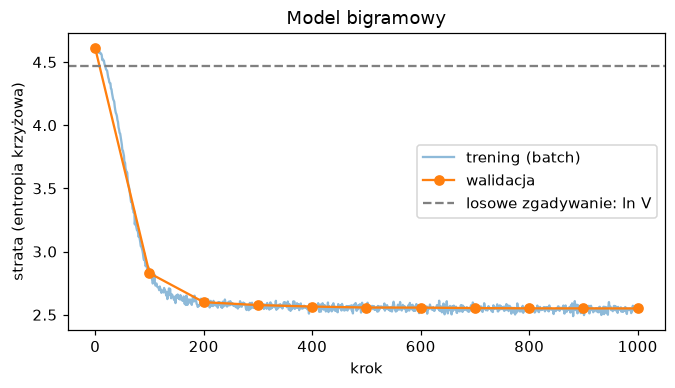

końcowa strata walidacyjna: 2.550  (perplexity 12.8)


In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hist["train_loss"], alpha=0.5, label="trening (batch)")
ax.plot(hist["eval_step"], hist["val_loss"], "o-", label="walidacja")
ax.axhline(math.log(tok.vocab_size), color="gray", ls="--", label="losowe zgadywanie: ln V")
ax.set_xlabel("krok")
ax.set_ylabel("strata (entropia krzyżowa)")
ax.legend()
ax.set_title("Model bigramowy")
plt.show()
print(f"końcowa strata walidacyjna: {hist['val_loss'][-1]:.3f}  (perplexity {math.exp(hist['val_loss'][-1]):.1f})")

In [10]:
sample = generate_naive(bigram, tok, "Litwo! ", max_new_tokens=300, block_size=1)
print(sample)

Litwo! tyłepoło pię, w szie krogani Sz pie pry wakrórzejewką.
Kro ustesz;
Odo ki te kakrałołośliegłe.
Wochałuko szedzach kraweniej,
Stemokusi sie, prycha ikto gł miu Dle wie ponanopokru,
Po prniedwsposzemie Maznktktrcie,
I sto wstna cię gąchowi stowało powi jedum pasził
Opęc pa go niemcznarawicieży prza pa


Litery układają się w "polsko wyglądające" zlepki, bo model zna częstości par znaków. Ale nie ma żadnej
pamięci: nie wie, w jakim jest słowie, wersie ani zdaniu. Perplexity mówi, że model waha się średnio między
kilkunastoma znakami. To nasza **linia bazowa**.

In [11]:
save_results("00_bigram", {"name": "Bigram (bez pamięci)", **hist, "sample": sample})

PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/00_bigram.json')

## 7. Czego nauczyły się embeddingi?

Każdy znak ma 16-wymiarowy wektor. Rzutujemy je na 2 wymiary metodą PCA (SVD wycentrowanej macierzy)
i kolorujemy według typu znaku. Nikt nie powiedział modelowi, co to samogłoska.

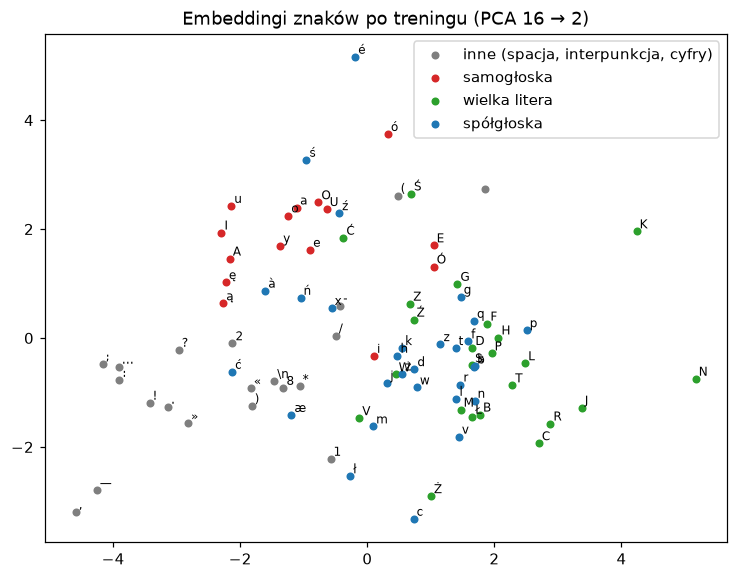

In [12]:
E = bigram.emb.weight.detach()
E = E - E.mean(0)
_, _, Vt = torch.linalg.svd(E, full_matrices=False)
coords = E @ Vt[:2].T


def char_group(c):
    if c.lower() in "aeiouyąęó":
        return "samogłoska", "C3"
    if c.isalpha():
        return ("wielka litera", "C2") if c.isupper() else ("spółgłoska", "C0")
    return "inne (spacja, interpunkcja, cyfry)", "C7"


fig, ax = plt.subplots(figsize=(8, 6))
seen = set()
for (px, py), c in zip(coords.tolist(), tok.chars):
    label, color = char_group(c)
    ax.scatter(px, py, color=color, s=18, label=None if label in seen else label)
    seen.add(label)
    ax.annotate(repr(c)[1:-1], (px, py), fontsize=8, xytext=(2, 2), textcoords="offset points")
ax.legend()
ax.set_title("Embeddingi znaków po treningu (PCA 16 → 2)")
plt.show()

Samogłoski zwykle lądują w jednej grupie, spółgłoski w innej, a znaki interpunkcyjne i nowa linia osobno:
znaki, po których następują podobne rzeczy, dostają podobne wektory.

## 8. Temperatura próbkowania

$p_i \propto \exp(z_i / \tau)$. Niska temperatura to bezpieczne, powtarzalne wybory; wysoka to więcej losowości.

In [13]:
for temperature in (0.3, 1.0, 1.6):
    print(f"--- temperatura {temperature} ---")
    print(generate_naive(bigram, tok, "Litwo! ", max_new_tokens=160, block_size=1, temperature=temperature, seed=1))

--- temperatura 0.3 ---
Litwo! sta po kie nie sta naczy ta po nie szy nie dze nie sze nanie sta wie sko wie mie sze sie szie dzy zie sty wiem wie nie po wie wie sze wy z o za sta m szy niemie
--- temperatura 1.0 ---
Litwo! śniedę krkim Szycanięcącitazyś rzedakanich dzużeną.
Sóróre k d śwawienkro wiamiedzbrubie ty,

I Hrziróże Hwda! jąłanię pa, «Bą w ardzielał ozcagać gole krówymie
--- temperatura 1.6 ---
Litwo! śninię, Hrzm;
Kstanięcącituzyś rzluja Koc — szejną.
Sóógreucz, śsawienkrow,
I żedzbsubik ty,

I Hrzirskry.
La!: sa
Iwęlpa, «Bąłóżardzkilułgozłbgż prólelkrówdmip


## Podsumowanie

- Tekst zamieniamy na liczby tokenizerem; my używamy znaków (V = 87), prawdziwe LLM-y używają BPE.
- Embedding to uczona tablica wektorów, a `nn.Embedding` to wybór wiersza.
- Model bez pamięci (bigram) osiąga stratę ok. 2,55 (perplexity ~13). **Każdy kolejny model musi mieć
  pamięć, żeby zejść niżej.** Pytanie tylko, jak ją zbudować.

**Dalej:** [`01_rnn.md`](01_rnn.md) → [`01_rnn.ipynb`](01_rnn.ipynb)